# Civilization II map scaling

Place the `.MP` file in the same folder as this notebook. Change the settings below, run the cells, compare both methods, and save the selected result. Requires NumPy and Matplotlib.


In [1]:
from pathlib import Path
from collections import defaultdict
from dataclasses import dataclass
import math
import struct

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

In [2]:
# Settings
input_file = Path("GREECE.MP")
scale_factor = 4
target_size = None              # Optional (width, height), e.g. (200, 320); overrides scale_factor.
method = "nearest"             # "nearest" or "categorical".
max_tiles = 32767
output_file = None              # None creates a name containing the size and method.
max_dimension = 256

# Relative bounds for the enlarged comparison: left, top, right, bottom.
zoom_bounds = (0.05, 0.05, 0.35, 0.40)

In [3]:
# Read and write the binary map without changing unrelated tile bytes.
TILE_OFFSET = 98
RECORD_SIZE = 6
MAX_TILES = 64000


@dataclass
class Civ2Map:
    width: int
    height: int
    flat: int
    seed: int
    minimap_width: int
    minimap_height: int
    starts_x: tuple
    starts_y: tuple
    tiles: bytes

    @classmethod
    def from_bytes(cls, data):
        if len(data) < TILE_OFFSET:
            raise ValueError("File is too short for the supported .MP format.")
        coord_width, height, area, flat, seed, mw, mh = struct.unpack_from('<7H', data)
        if coord_width == 0 or coord_width % 2 or height == 0:
            raise ValueError("Invalid map dimensions: Civ2 X width must be positive and even.")
        width = coord_width // 2
        if area != width * height:
            raise ValueError("Header tile count disagrees with the dimensions.")
        expected = TILE_OFFSET + RECORD_SIZE * area
        if len(data) != expected:
            raise ValueError(f"Unsupported layout: expected {expected:,} bytes, got {len(data):,}.")
        if flat not in (0, 1):
            raise ValueError("Unsupported wrapping flag; expected 0 or 1.")
        xs = struct.unpack_from('<21h', data, 14)
        ys = struct.unpack_from('<21h', data, 56)
        for slot, (x, y) in enumerate(zip(xs, ys)):
            if x == y == -1:
                continue
            if not (0 <= x < coord_width and 0 <= y < height and (x - y) % 2 == 0):
                raise ValueError(f"Invalid starting coordinates in slot {slot}: {(x, y)}.")
        tiles = data[TILE_OFFSET:]
        if any((v & 15) > 10 for v in tiles[::RECORD_SIZE]):
            raise ValueError("Unknown terrain IDs: this script supports standard Civ2 terrain slots 0..10.")
        return cls(width, height, flat, seed, mw, mh, xs, ys, tiles)

    def to_bytes(self):
        header = struct.pack('<7H', 2 * self.width, self.height,
                             self.width * self.height, self.flat, self.seed,
                             self.minimap_width, self.minimap_height)
        return (header + struct.pack('<21h', *self.starts_x)
                + struct.pack('<21h', *self.starts_y) + self.tiles)

    def record(self, index):
        return self.tiles[RECORD_SIZE * index:RECORD_SIZE * (index + 1)]

In [4]:
# Find neighboring tiles on the staggered grid and choose a source record.
def samples_at(source, x, y):
    """Return (index, interpolation weight, squared distance) on staggered rows.

    In Civ2 coordinates, stored column c in row y has x = 2*c + (y % 2).
    Wrap horizontally only for round maps, and extend boundary rows vertically.
    """
    y = min(max(y, 0.0), source.height - 1)
    row0 = math.floor(y)
    rows = ((row0, 1 - (y - row0)), (min(row0 + 1, source.height - 1), y - row0))
    samples = {}
    for row, row_weight in rows:
        if row_weight <= 0:
            continue
        col = (x - row % 2) / 2
        if source.flat:
            col = min(max(col, 0.0), source.width - 1)
        col0 = math.floor(col)
        for raw_col, col_weight in ((col0, 1 - (col - col0)), (col0 + 1, col - col0)):
            if col_weight <= 0:
                continue
            actual_col = (min(max(raw_col, 0), source.width - 1)
                          if source.flat else raw_col % source.width)
            sx = 2 * raw_col + row % 2
            index = row * source.width + actual_col
            weight = row_weight * col_weight
            distance = (sx - x) ** 2 + (row - y) ** 2
            if index in samples:
                old_weight, old_distance = samples[index]
                samples[index] = (old_weight + weight, min(old_distance, distance))
            else:
                samples[index] = (weight, distance)
    return [(index, weight, distance) for index, (weight, distance) in samples.items()]


def choose_source(source, samples, method):
    if method == 'nearest':
        return min(samples, key=lambda p: (p[2], -p[1], p[0]))[0]
    # Include the river bit, but exclude animation/resource suppression flags.
    scores = defaultdict(float)
    for index, weight, _ in samples:
        scores[source.tiles[RECORD_SIZE * index] & 0x8F] += weight
    # Resolve ties using the closest source tile, deterministically.
    closest = sorted(samples, key=lambda p: (p[2], -p[1], p[0]))
    best_score = max(scores.values())
    category = next(source.tiles[RECORD_SIZE * i] & 0x8F for i, _, _ in closest
                    if math.isclose(scores[source.tiles[RECORD_SIZE * i] & 0x8F],
                                    best_score, rel_tol=0, abs_tol=1e-12))
    donors = [p for p in samples if source.tiles[RECORD_SIZE * p[0]] & 0x8F == category]
    return max(donors, key=lambda p: (p[1], -p[2], -p[0]))[0]

In [5]:
# Resize the terrain and move the civilization starting positions.
def scale_starts(source, width, height, tiles):
    xs, ys = [], []
    wrapped = source.flat == 0
    for old_x, old_y in zip(source.starts_x, source.starts_y):
        if old_x == old_y == -1:
            xs.append(-1)
            ys.append(-1)
            continue
        # Inverse of the cell-centered mapping used to resample the terrain.
        target_x = (old_x + 0.5) * width / source.width - 0.5
        target_y = (old_y + 0.5) * height / source.height - 0.5
        was_land = source.tiles[RECORD_SIZE * (old_y * source.width + old_x // 2)] & 15 != 10
        best = None
        for y in range(height):
            for col in range(width):
                if was_land and tiles[RECORD_SIZE * (y * width + col)] & 15 == 10:
                    continue
                x = 2 * col + y % 2
                dx = abs(x - target_x)
                if wrapped:
                    dx %= 2 * width
                    dx = min(dx, 2 * width - dx)
                candidate = (dx * dx + (y - target_y) ** 2, y, x)
                if best is None or candidate < best:
                    best = candidate
        if best is None:
            raise ValueError("A land starting position has no land left after resizing.")
        _, y, x = best
        xs.append(x)
        ys.append(y)
    return tuple(xs), tuple(ys)


def resize_map(source, width, height, method='nearest', max_tiles=MAX_TILES):
    if method not in ('nearest', 'categorical'):
        raise ValueError("Method must be 'nearest' or 'categorical'.")
    if not (1 <= max_tiles <= MAX_TILES):
        raise ValueError("Tile limit must be between 1 and 64,000.")
    if not (1 <= width <= 16383 and 1 <= height <= 32767):
        raise ValueError("Dimensions exceed the supported coordinate range.")
    if width * height > max_tiles:
        raise ValueError(f"Requested {width * height:,} tiles; limit is {max_tiles:,}.")
    if (width, height) == (source.width, source.height):
        return source  # Preserve all bytes, including existing minimap settings.
    output = bytearray()
    for y in range(height):
        sy = (y + 0.5) * source.height / height - 0.5
        for col in range(width):
            x = 2 * col + y % 2
            sx = (x + 0.5) * source.width / width - 0.5
            index = choose_source(source, samples_at(source, sx, sy), method)
            output.extend(source.record(index))
    xs, ys = scale_starts(source, width, height, output)
    result = Civ2Map(width, height, source.flat, source.seed,
                     (2 * width + 3) // 4, (height + 3) // 4, xs, ys, bytes(output))
    Civ2Map.from_bytes(result.to_bytes())
    return result

In [6]:
# Colors follow the standard Civ2 terrain slots.
terrain_names = ["Desert", "Plains", "Grassland", "Forest", "Hills", "Mountains",
                 "Tundra", "Glacier", "Swamp", "Jungle", "Ocean"]
terrain_colors = ["#d9bd7b", "#c9c177", "#70b952", "#306847", "#958853", "#796e60",
                  "#bec6aa", "#f0f5f5", "#548b7f", "#24583e", "#3975ae"]


def plot_map(ax, world, title, bounds=(0, 0, 1, 1)):
    left, top, right, bottom = bounds
    if not (0 <= left < right <= 1 and 0 <= top < bottom <= 1):
        raise ValueError("Plot bounds must satisfy 0 <= left < right <= 1 and 0 <= top < bottom <= 1.")

    records = np.frombuffer(world.tiles, dtype=np.uint8).reshape(world.height, world.width, 6)
    rows, cols = np.indices((world.height, world.width))
    x = 2 * cols + rows % 2
    y = rows
    visible = ((x >= 2 * world.width * left - 1) & (x <= 2 * world.width * right + 1)
               & (y >= world.height * top - 1) & (y <= world.height * bottom + 1))
    centers = np.column_stack((x[visible], y[visible]))
    diamonds = np.array([[-1, 0], [0, -1], [1, 0], [0, 1]])
    vertices = centers[:, None, :] + diamonds
    colors = np.array(terrain_colors)[records[..., 0][visible] & 15]
    ax.add_collection(PolyCollection(vertices, facecolors=colors, edgecolors="none", antialiased=False))

    # Small blue diamonds mark river tiles; they do not imply flow direction.
    rivers = (records[..., 0][visible] & 128) != 0
    river_vertices = centers[rivers, None, :] + 0.25 * diamonds
    ax.add_collection(PolyCollection(river_vertices, facecolors="#064fce", edgecolors="none"))

    starts = [(sx, sy) for sx, sy in zip(world.starts_x, world.starts_y) if sx >= 0]
    if starts:
        sx, sy = zip(*starts)
        ax.scatter(sx, sy, marker="*", s=45, c="#ef3c3c", edgecolors="black", linewidths=0.4)

    ax.set_xlim(2 * world.width * left - 1, 2 * world.width * right)
    ax.set_ylim(world.height * bottom, world.height * top - 1)
    ax.set_aspect(0.5)
    ax.set_title(title, fontsize=11)
    ax.axis("off")

In [7]:
# Load the original map.
source_bytes = input_file.read_bytes()
original = Civ2Map.from_bytes(source_bytes)
assert original.to_bytes() == source_bytes

print(f"Original: {original.width} × {original.height} = {original.width * original.height:,} tiles")
print(f"World: {'flat' if original.flat else 'wraps horizontally'}")
print(f"Assigned starting positions: {sum(x >= 0 for x in original.starts_x)}")

Original: 50 × 80 = 4,000 tiles
World: flat
Assigned starting positions: 5


In [8]:
# Choose the output dimensions. Width means actual tiles per row, not doubled Civ2 X coordinates.
if method not in ("nearest", "categorical"):
    raise ValueError('method must be "nearest" or "categorical".')



if target_size is None:
    scale_factor = min(
        math.sqrt(max_tiles / (original.width * original.height)),
        max_dimension / (2 * original.width),
        max_dimension / original.height
    )
    width = max(1, math.floor(original.width * scale_factor))
    height = max(1, math.floor(original.height * scale_factor))
else:
    width, height = target_size
    if not isinstance(width, int) or not isinstance(height, int):
        raise ValueError("target_size must contain two integers.")

print(f"Target: {width} × {height} = {width * height:,} tiles")
print(f"Tile limit: {max_tiles:,}")

# Generate both methods for comparison. The final cell saves only the selected method.
scaled_maps = {name: resize_map(original, width, height, name, max_tiles)
               for name in ("nearest", "categorical")}
print(f"Selected method: {method}")

Target: 128 × 204 = 26,112 tiles
Tile limit: 60,000
Selected method: nearest


Nearest copies the closest source tile. Categorical interpolation combines terrain-category weights and selects the strongest category; it does not average terrain codes. River and non-river variants are separate categories. Both methods use the staggered grid and copy complete tile records.


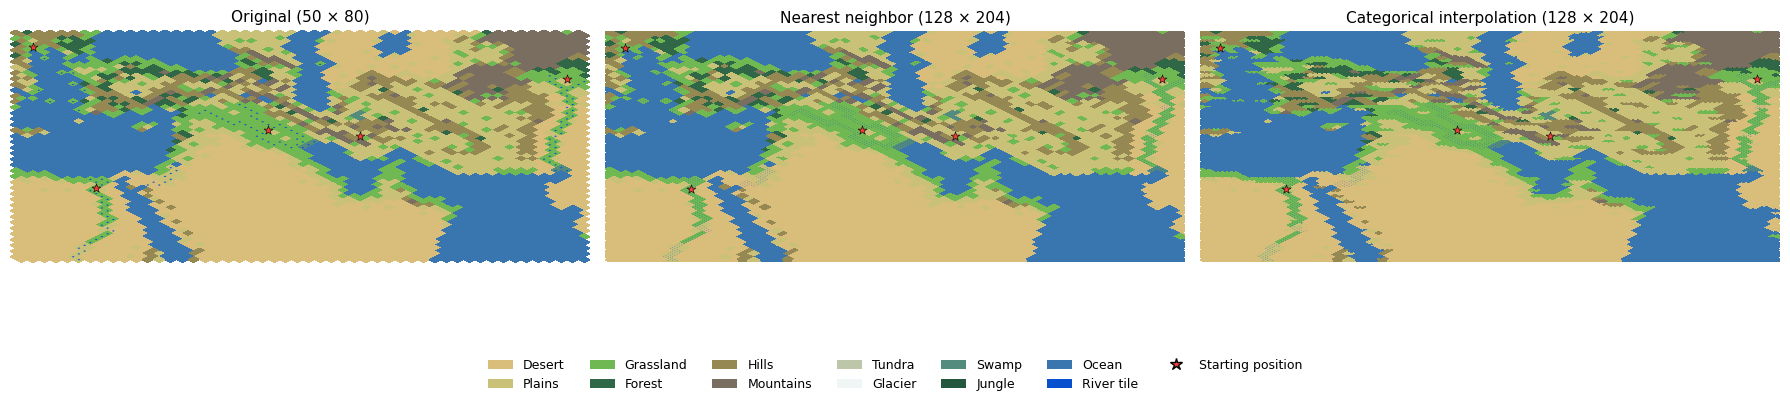

In [9]:
# Compare the full maps at the same geographic extent.
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
plot_map(axes[0], original, f"Original ({original.width} × {original.height})")
plot_map(axes[1], scaled_maps["nearest"], f"Nearest neighbor ({width} × {height})")
plot_map(axes[2], scaled_maps["categorical"], f"Categorical interpolation ({width} × {height})")

legend = [Patch(facecolor=color, label=name) for color, name in zip(terrain_colors, terrain_names)]
legend += [Patch(facecolor="#064fce", label="River tile"),
           Line2D([], [], marker="*", color="none", markerfacecolor="#ef3c3c",
                  markeredgecolor="black", markersize=9, label="Starting position")]
fig.legend(handles=legend, loc="lower center", ncol=7, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

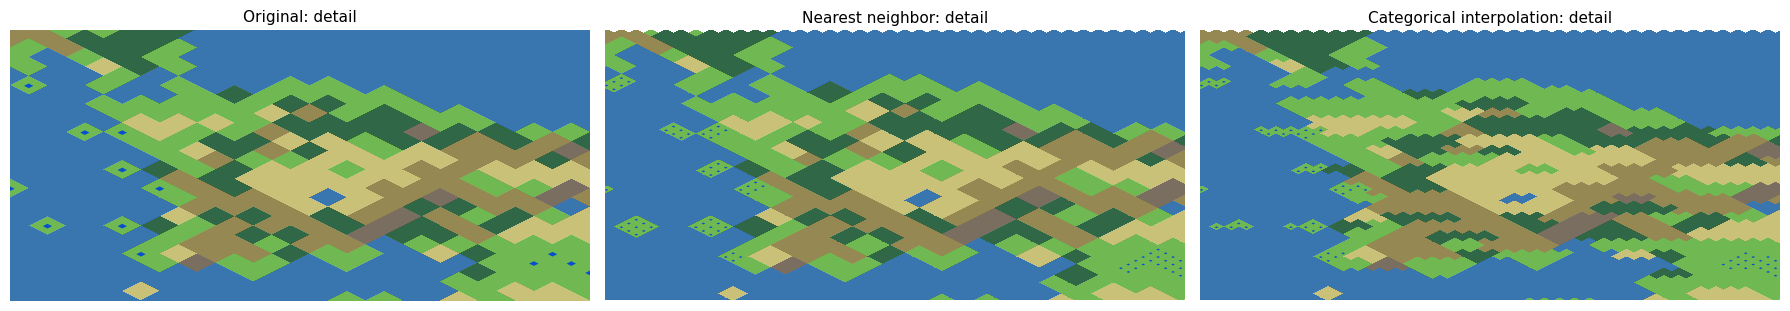

In [10]:
# Compare a smaller region. Change zoom_bounds in the settings to inspect another area.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_map(axes[0], original, "Original: detail", zoom_bounds)
plot_map(axes[1], scaled_maps["nearest"], "Nearest neighbor: detail", zoom_bounds)
plot_map(axes[2], scaled_maps["categorical"], "Categorical interpolation: detail", zoom_bounds)
fig.tight_layout()
plt.show()

Nearest retains more small features; categorical interpolation may smooth boundaries and remove narrow features. Neither adds new geographic detail, and rivers become wider when enlarged. The resource seed is retained, but resources and huts follow the new coordinates. Binary checks are included; loading in the patched game remains untested.


In [11]:
# Save the selected map. Rerunning this cell replaces the generated output, never the input map.
selected = scaled_maps[method]
destination = (Path(output_file) if output_file is not None else
               input_file.with_name(f"{input_file.stem}_{width}x{height}_{method}.MP"))
if destination.resolve() == input_file.resolve():
    raise ValueError("Choose an output filename different from the original map.")

result_bytes = selected.to_bytes()
checked = Civ2Map.from_bytes(result_bytes)
assert len(result_bytes) == TILE_OFFSET + RECORD_SIZE * width * height
assert (checked.width, checked.height) == (width, height)
assert checked.to_bytes() == result_bytes
destination.write_bytes(result_bytes)

print(f"Saved: {destination}")
print(f"{width:,} × {height:,} = {width * height:,} tiles; {len(result_bytes):,} bytes")
print("Binary checks passed. Load the .MP file in your patched Civilization II installation.")

Saved: GREECE_128x204_nearest.MP
128 × 204 = 26,112 tiles; 156,770 bytes
Binary checks passed. Load the .MP file in your patched Civilization II installation.
